In [1]:
import pandas as pd

In [2]:
df = pd.read_csv("D:\\studies\\stats consult\\screen time dataset countries\\country_wise_analysis_addiction.csv")
df1 = pd.read_excel("D:\\studies\\stats consult\\WHR26_Data_Figure_2.1.xlsx")

In [3]:
countries_to_keep = [
    "United States of America",
    "Finland",
    "Iceland",
    "Denmark",
    "Germany",
    "France",
    "South Korea",
    "Japan",
    "India",
]

dfst = df[df["country"].isin(countries_to_keep)].copy()
dfst

,country,tiktok_minutes_daily,instagram_minutes_daily,attention_span_score,dopamine_dependency_score,sleep_hours,addiction_score,ASI,MHRI,addiction_rank
20,Denmark,123.978685,98.565692,81.454635,22.254438,7.176097,58.371359,94.488281,41.166498,61
26,Finland,124.747728,100.750444,81.208486,22.549817,6.900546,58.885850,95.221884,45.610054,37
27,France,134.213522,97.084804,80.725139,23.129833,6.838016,58.989367,94.848901,43.373841,30
28,Germany,120.911786,96.785840,81.858531,21.769763,6.805920,58.921410,96.073058,47.670342,33
35,Iceland,119.311498,90.606558,82.506829,20.991806,6.916504,57.444164,93.896523,44.183181,91
36,India,119.066822,96.720734,82.017704,21.578756,7.118058,58.326093,95.073431,45.433015,62
43,Japan,126.319497,103.981760,80.808229,23.030126,6.897329,59.369149,95.708172,42.092840,19
77,South Korea,124.755618,109.299636,80.495396,23.405525,6.846347,59.811264,96.217003,45.097176,12


In [4]:
whr_country_names = {
    "United States of America": "United States",
    "Finland": "Finland",
    "Iceland": "Iceland",
    "Denmark": "Denmark",
    "Germany": "Germany",
    "France": "France",
    "South Korea": "Republic of Korea",
    "Japan": "Japan",
    "India": "India",
}

source_to_selected = {
    source_name: selected_name
    for selected_name, source_name in whr_country_names.items()
}

dfwhr = df1[
    df1["Country name"].isin(whr_country_names.values())
    & df1["Year"].between(2015, 2026)
].copy()
dfwhr["Country"] = dfwhr["Country name"].map(source_to_selected)
dfwhr

,Year,Rank,Country name,Life evaluation (3-year average),Lower whisker,Upper whisker,Explained by: Log GDP per capita,Explained by: Social support,Explained by: Healthy life expectancy,Explained by: Freedom to make life choices,Explained by: Generosity,Explained by: Perceptions of corruption,Dystopia + residual,Country
0,2025,1,Finland,7.764,7.690,7.837,1.915,1.638,0.939,1.105,0.093,0.491,1.582,Finland
1,2025,2,Iceland,7.540,7.449,7.630,1.971,1.720,0.996,1.105,0.187,0.187,1.373,Iceland
2,2025,3,Denmark,7.539,7.446,7.631,1.986,1.633,0.930,1.081,0.125,0.474,1.310,Denmark
16,2025,17,Germany,6.882,6.789,6.975,1.948,1.490,0.876,0.948,0.145,0.349,1.128,Germany
22,2025,23,United States,6.816,6.724,6.908,2.002,1.516,0.678,0.776,0.155,0.155,1.534,United States of America
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1504,2015,16,Germany,6.994,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Germany
1520,2015,32,France,6.478,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,France
1541,2015,53,Japan,5.921,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Japan
1546,2015,58,Republic of Korea,5.835,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,South Korea


In [5]:
dfwhr_by_country = {
    country: dfwhr[dfwhr["Country"] == country].sort_values("Year").copy()
    for country in whr_country_names
}

dfwhr_usa = dfwhr_by_country["United States of America"]
dfwhr_finland = dfwhr_by_country["Finland"]
dfwhr_iceland = dfwhr_by_country["Iceland"]
dfwhr_denmark = dfwhr_by_country["Denmark"]
dfwhr_germany = dfwhr_by_country["Germany"]
dfwhr_france = dfwhr_by_country["France"]
dfwhr_south_korea = dfwhr_by_country["South Korea"]
dfwhr_japan = dfwhr_by_country["Japan"]
dfwhr_india = dfwhr_by_country["India"]

{name: country_df.shape for name, country_df in dfwhr_by_country.items()}

{'United States of America': (11, 14),
 'Finland': (11, 14),
 'Iceland': (11, 14),
 'Denmark': (11, 14),
 'Germany': (11, 14),
 'France': (11, 14),
 'South Korea': (11, 14),
 'Japan': (11, 14),
 'India': (11, 14)}

In [6]:
screentimebehav= pd.read_csv("D:\\studies\\stats consult\\screen time dataset countries\\screen_time_behavior.csv")
screentimebehav

,user_id,year,country,age_group,gender,platform,weekday_screen_hours,weekend_screen_hours,multitasking_frequency,focus_span_minutes,physical_activity_hours_weekly
0,8050,2038,Germany,Children,Other,Reddit,4.12,10.76,10.72,13.09,5.58
1,13262,2018,South Korea,Senior,Other,Twitch,3.78,10.32,64.22,23.52,5.41
2,8948,2025,Mexico,Young Adult,Female,Instagram,8.65,10.19,60.37,8.49,3.66
3,13114,2012,Spain,Young Adult,Other,Snapchat,4.29,8.24,6.10,14.25,5.11
4,2307,2030,Brazil,Adult,Female,Snapchat,4.51,5.17,90.75,16.70,3.63
...,...,...,...,...,...,...,...,...,...,...,...
49995,6930,2059,Spain,Adult,Other,Discord,2.37,8.13,7.97,9.79,6.23
49996,825,2022,Spain,Teen,Male,X/Twitter,7.08,9.95,52.58,15.02,5.13
49997,20403,2022,Canada,Senior,Female,Reddit,5.72,8.70,16.52,19.25,2.60
49998,14453,2031,UK,Young Adult,Other,YouTube,6.68,10.67,48.75,29.51,2.08


In [7]:
screen_country_names = {
    "United States of America": "USA",
    "Finland": "Finland",
    "Iceland": "Iceland",
    "Denmark": "Denmark",
    "Germany": "Germany",
    "France": "France",
    "South Korea": "South Korea",
    "Japan": "Japan",
    "India": "India",
}

screen_source_to_selected = {
    source_name: selected_name
    for selected_name, source_name in screen_country_names.items()
}

screentimebehav = screentimebehav[
    screentimebehav["country"].isin(screen_country_names.values())
].copy()
screentimebehav["Country"] = screentimebehav["country"].map(screen_source_to_selected)
screentimebehav

,user_id,year,country,age_group,gender,platform,weekday_screen_hours,weekend_screen_hours,multitasking_frequency,focus_span_minutes,physical_activity_hours_weekly,Country
0,8050,2038,Germany,Children,Other,Reddit,4.12,10.76,10.72,13.09,5.58,Germany
1,13262,2018,South Korea,Senior,Other,Twitch,3.78,10.32,64.22,23.52,5.41,South Korea
5,7216,2026,USA,Senior,Male,Twitch,5.63,7.52,11.69,17.48,3.59,United States of America
9,3306,2033,South Korea,Adult,Other,LinkedIn,5.72,9.90,81.98,25.97,5.41,South Korea
10,10022,2027,India,Children,Female,YouTube,4.91,7.53,16.39,18.80,4.59,India
...,...,...,...,...,...,...,...,...,...,...,...,...
49985,11518,2042,Japan,Children,Male,Discord,5.80,7.63,80.49,16.06,1.57,Japan
49987,11087,2060,India,Teen,Other,Facebook,9.79,5.54,81.38,14.01,8.20,India
49988,6589,2041,South Korea,Adult,Female,Facebook,6.99,9.83,99.07,18.49,5.55,South Korea
49990,11246,2011,South Korea,Senior,Other,Facebook,6.03,7.86,61.93,11.10,3.36,South Korea


In [8]:
screentimebehav15 = screentimebehav[screentimebehav["year"] == 2015].copy()
screentimebehav16 = screentimebehav[screentimebehav["year"] == 2016].copy()
screentimebehav17 = screentimebehav[screentimebehav["year"] == 2017].copy()
screentimebehav18 = screentimebehav[screentimebehav["year"] == 2018].copy()
screentimebehav15, screentimebehav16, screentimebehav17, screentimebehav18

(       user_id  year      country age_group  gender   platform  \
 41        4920  2015  South Korea      Teen  Female     Reddit   
 280      16759  2015       France    Senior   Other   LinkedIn   
 396      17728  2015          USA    Senior   Other     Reddit   
 512      16776  2015      Germany      Teen  Female    YouTube   
 658       5275  2015      Germany    Senior  Female  Instagram   
 ...        ...   ...          ...       ...     ...        ...   
 49382    16851  2015          USA  Children  Female    YouTube   
 49440     1419  2015          USA     Adult   Other   Facebook   
 49468     4195  2015       France    Senior   Other     Twitch   
 49783     6663  2015        India     Adult  Female    YouTube   
 49802    19984  2015      Germany     Adult    Male   Snapchat   
 
        weekday_screen_hours  weekend_screen_hours  multitasking_frequency  \
 41                     4.53                  7.18                   40.04   
 280                    6.76          

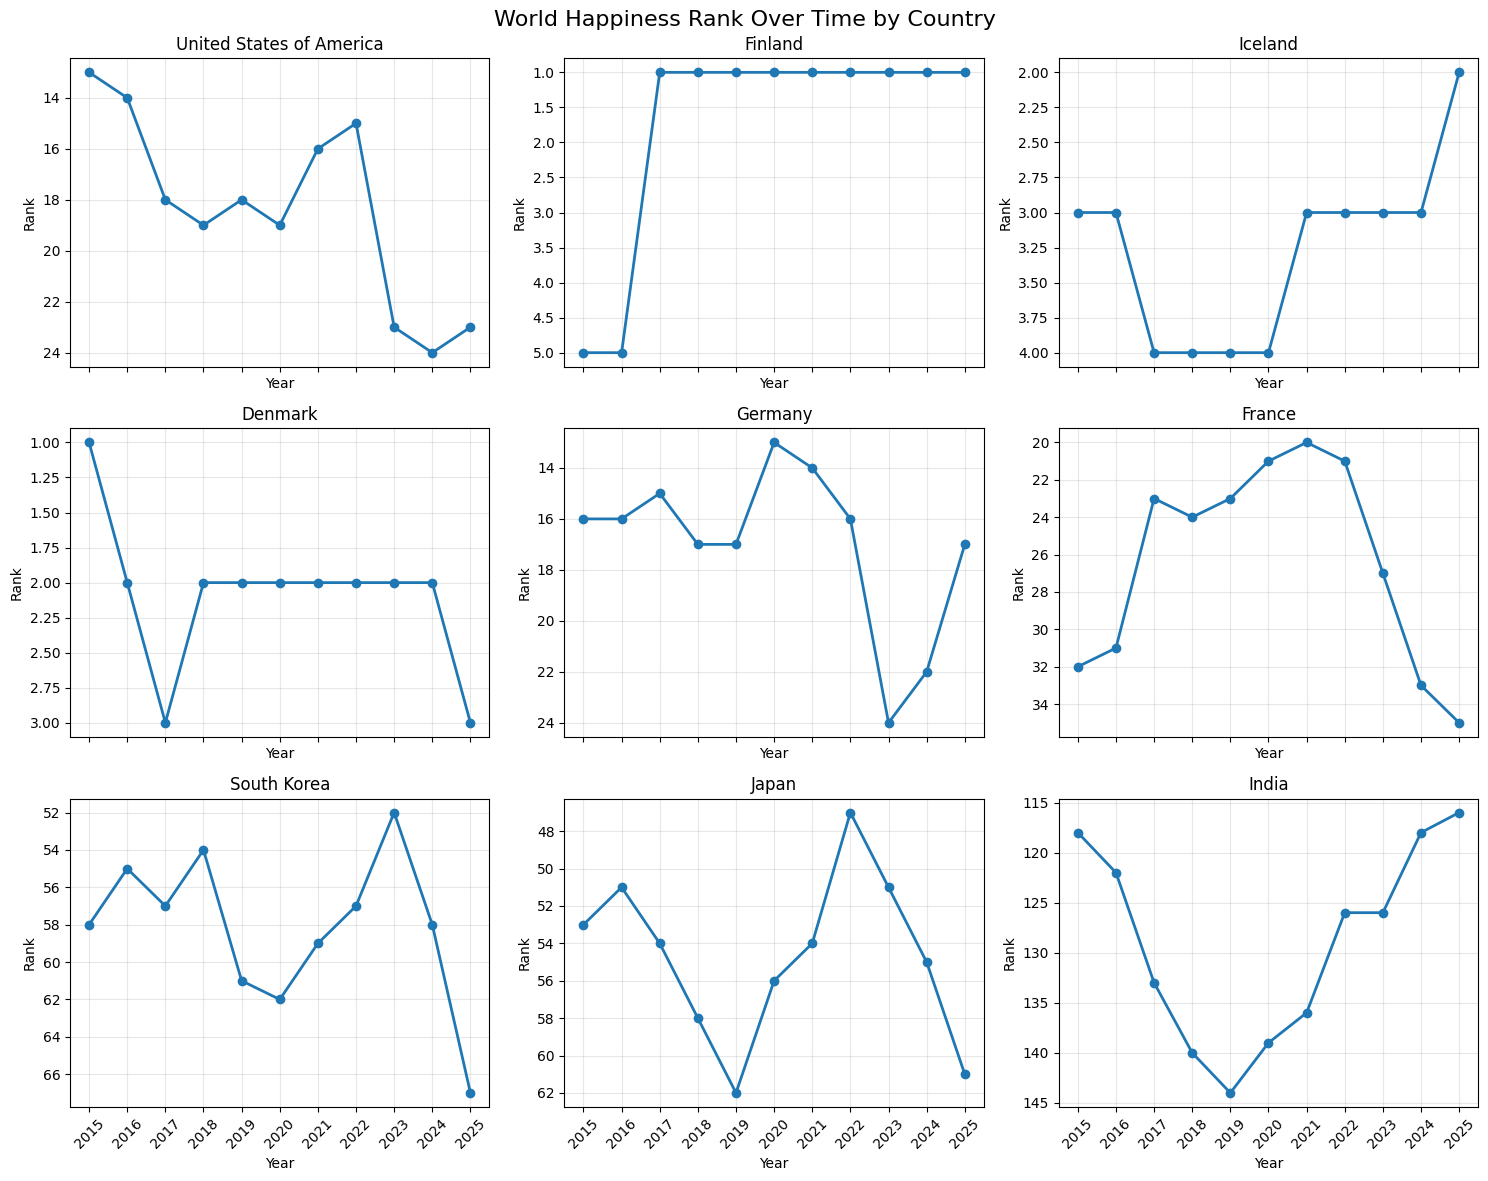

In [9]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(3, 3, figsize=(15, 12), sharex=True)
axes = axes.ravel()

for axis, (country, country_df) in zip(axes, dfwhr_by_country.items()):
    country_df = country_df.sort_values("Year")
    axis.plot(country_df["Year"], country_df["Rank"], marker="o", linewidth=2)
    axis.set_title(country)
    axis.set_xlabel("Year")
    axis.set_ylabel("Rank")
    axis.set_xticks(sorted(country_df["Year"].unique()))
    axis.tick_params(axis="x", rotation=45)
    axis.invert_yaxis()
    axis.grid(True, alpha=0.3)

fig.suptitle("World Happiness Rank Over Time by Country", fontsize=16)
fig.tight_layout()
plt.show()
#saving graphs
fig.savefig("world_happiness_rank.png", dpi=600, bbox_inches="tight")

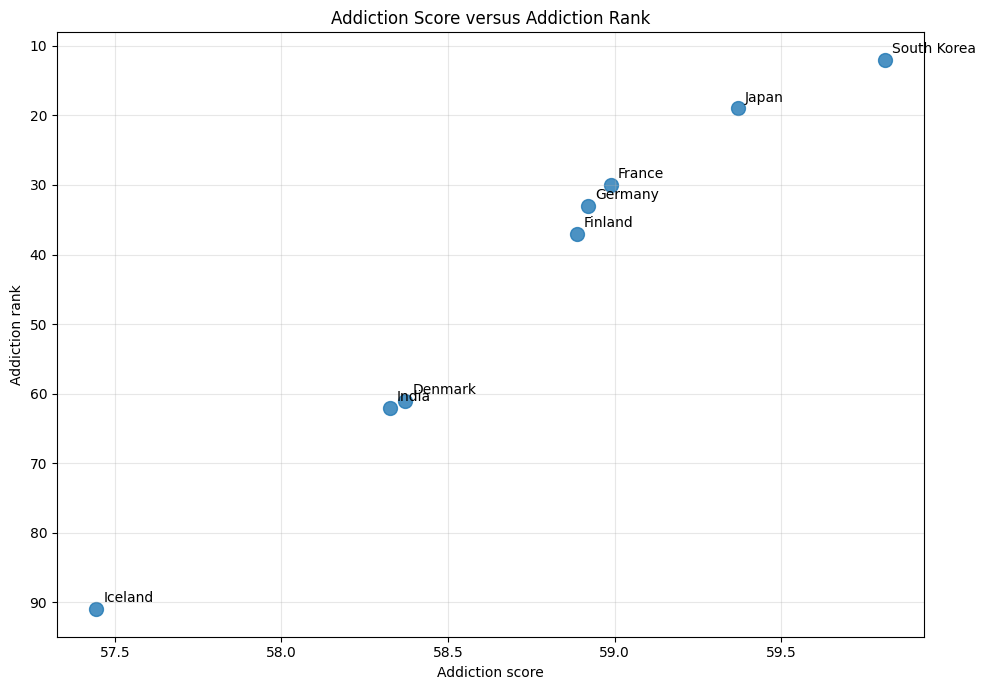

Finland: no matching screen-time data
Iceland: no matching screen-time data
Denmark: no matching screen-time data


In [ ]:
import matplotlib.pyplot as plt
import plotly.express as px
from pathlib import Path

# Addiction score versus addiction rank for each available country.
addiction_plot_df = dfst[["country", "addiction_score", "addiction_rank"]].dropna().copy()

fig, axis = plt.subplots(figsize=(10, 7))
axis.scatter(
    addiction_plot_df["addiction_score"],
    addiction_plot_df["addiction_rank"],
    s=100,
    alpha=0.8,
)

for _, row in addiction_plot_df.iterrows():
    axis.annotate(
        row["country"],
        (row["addiction_score"], row["addiction_rank"]),
        xytext=(5, 5),
        textcoords="offset points",
    )

axis.set_title("Addiction Score versus Addiction Rank")
axis.set_xlabel("Addiction score")
axis.set_ylabel("Addiction rank")
axis.invert_yaxis()
axis.grid(True, alpha=0.3)
fig.tight_layout()
plt.show()

# Average weekday/weekend screen time by country and year.
screen_time_by_country_year = (
    screentimebehav.assign(
        screen_time_hours=(
            screentimebehav["weekday_screen_hours"]
            + screentimebehav["weekend_screen_hours"]
        )
        / 2
    )
    .groupby(["Country", "year"], as_index=False)["screen_time_hours"]
    .mean()
)

rank_screen_time = dfwhr.merge(
    screen_time_by_country_year,
    left_on=["Country", "Year"],
    right_on=["Country", "year"],
    how="inner",
)

graphs_dir = Path("graphs")
graphs_dir.mkdir(exist_ok=True)

# Create one interactive bubble figure per country.
bubble_figures = {}
for country in whr_country_names:
    country_df = rank_screen_time[rank_screen_time["Country"] == country].copy()

    if country_df.empty:
        print(f"{country}: no matching screen-time data")
        continue

    min_screen_time = country_df["screen_time_hours"].min()
    max_screen_time = country_df["screen_time_hours"].max()

    if max_screen_time == min_screen_time:
        country_df["bubble_size"] = 25
    else:
        country_df["bubble_size"] = (
            10
            + 35
            * (country_df["screen_time_hours"] - min_screen_time)
            / (max_screen_time - min_screen_time)
        )

    bubble_fig = px.scatter(
        country_df, 
        x="Year",
        y="Rank",
        size="bubble_size",
        size_max=45,
        hover_name="Country",
        hover_data={
            "Year": True,
            "Rank": True,
            "screen_time_hours": ":.3f",
            "bubble_size": False,
        },
        title=f"{country}: Happiness Rank and Average Screen Time",
        labels={
            "Rank": "Happiness rank",
            "screen_time_hours": "Average screen time (hours)",
        },
    )
    bubble_fig.update_yaxes(autorange="reversed")
    bubble_fig.update_layout(
        xaxis_title="Year",
        yaxis_title="Happiness rank",
        template="plotly_white",
    )
    bubble_figures[country] = bubble_fig
    bubble_fig.show()

    # Save a static PNG without requiring Plotly's Kaleido backend.
    png_fig, png_axis = plt.subplots(figsize=(8, 6))
    png_axis.scatter(
        country_df["Year"],
        country_df["Rank"],
        s=country_df["bubble_size"] * 8,
        alpha=0.65,
        edgecolors="black",
        linewidths=0.5,
    )
    png_axis.set_title(f"{country}: Happiness Rank and Average Screen Time")
    png_axis.set_xlabel("Year")
    png_axis.set_ylabel("Happiness rank")
    png_axis.set_xticks(sorted(country_df["Year"].unique()))
    png_axis.tick_params(axis="x", rotation=45)
    png_axis.invert_yaxis()
    png_axis.grid(True, alpha=0.3)
    png_fig.tight_layout()
    png_fig.savefig(
        graphs_dir / f"{country}_happiness_screen_time.png",
        dpi=200,
        bbox_inches="tight",
    )
    plt.close(png_fig)

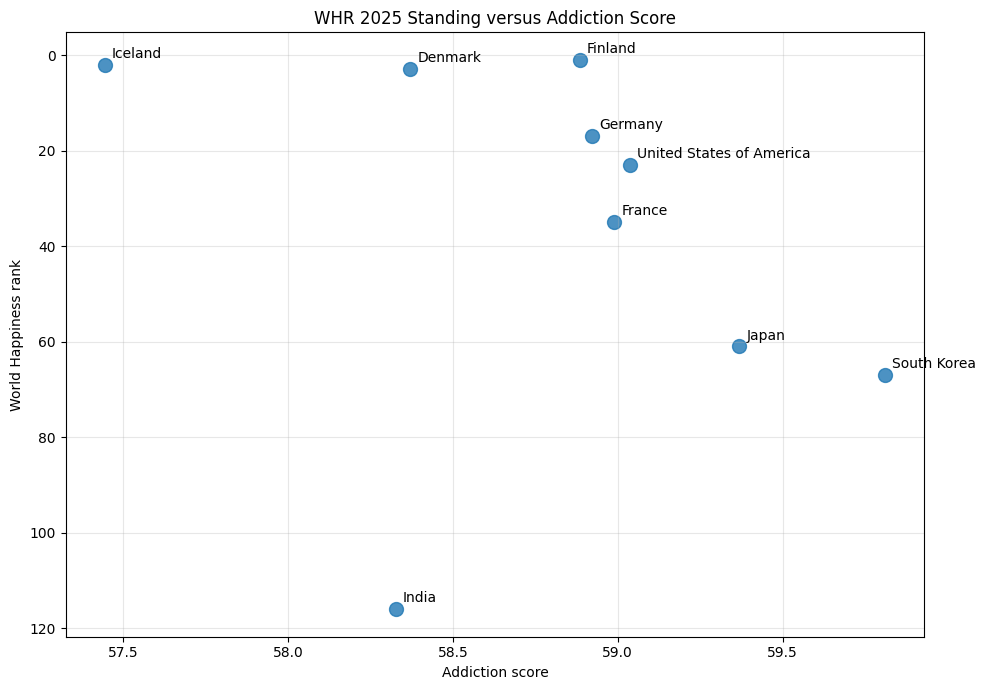

WHR 2026 data unavailable; graph uses the latest available year: 2025.


In [11]:
import matplotlib.pyplot as plt

requested_year = 2026
available_years = dfwhr["Year"].dropna().astype(int)
whr_year = requested_year if requested_year in available_years.values else available_years.max()

whr_standing = dfwhr.loc[
    dfwhr["Year"] == whr_year,
    ["Country", "Rank"],
].copy()

addiction_for_plot = df.loc[
    df["country"].isin(countries_to_keep + ["USA"]),
    ["country", "addiction_score"],
].copy()
addiction_for_plot["Country"] = addiction_for_plot["country"].replace(
    {"USA": "United States of America"}
)
addiction_for_plot = addiction_for_plot[["Country", "addiction_score"]]

whr_addiction = whr_standing.merge(
    addiction_for_plot,
    on="Country",
    how="inner",
).dropna()

fig, axis = plt.subplots(figsize=(10, 7))
axis.scatter(
    whr_addiction["addiction_score"],
    whr_addiction["Rank"],
    s=100,
    alpha=0.8,
)

for _, row in whr_addiction.iterrows():
    axis.annotate(
        row["Country"],
        (row["addiction_score"], row["Rank"]),
        xytext=(5, 5),
        textcoords="offset points",
    )

axis.set_title(f"WHR {whr_year} Standing versus Addiction Score")
axis.set_xlabel("Addiction score")
axis.set_ylabel("World Happiness rank")
axis.invert_yaxis()
axis.grid(True, alpha=0.3)
fig.tight_layout()
plt.show()

if whr_year != requested_year:
    print(f"WHR 2026 data unavailable; graph uses the latest available year: {whr_year}.")

fig.savefig(f"whr_{whr_year}_addiction_score.png", dpi=800, bbox_inches="tight")

In [3]:
#finalizing dataset 
df_nordic = pd.read_csv("screen time dataset countries/nordic_screentime_progression_2014_2025.csv")
df_nordic

,Country,Year_Period,Avg_Daily_ScreenTime_Adults,Avg_Daily_ScreenTime_Youth,Key_Drivers_Observations
0,Finland,2014 - 2016,3 hrs 15 min - 3 hrs 45 min,3 hrs 50 min - 4 hrs 10 min,Shift to 4G networks; rapid adoption of smartp...
1,Finland,2017 - 2019,4 hrs 10 min - 4 hrs 30 min,4 hrs 30 min - 4 hrs 50 min,"Rise of short-form video apps, streaming platf..."
2,Finland,2020 - 2021 (Pandemic Peak),5 hrs 30 min - 5 hrs 50 min,6 hrs 15 min +,"Historic surge driven by remote schooling, wor..."
3,Finland,2022 - 2023,5 hrs 05 min - 5 hrs 20 min,5 hrs 46 min,Post-pandemic normalization; overall screen us...
4,Finland,2024 - 2025,5 hrs 06 min - 5 hrs 24 min,5 hrs 30 min - 5 hrs 45 min,Market plateau. Screen time focus shifted heav...
5,Iceland,2014 - 2016,3 hrs 30 min - 4 hrs,5 hrs 24 min - 6 hrs,Widespread 4G deployment; heavy adoption of Sn...
6,Iceland,2017 - 2019,4 hrs 15 min - 4 hrs 45 min,6 hrs 10 min - 6 hrs 30 min,"Surge in mobile video consumption, streaming a..."
7,Iceland,2020 - 2021 (Pandemic Peak),5 hrs 45 min - 6 hrs 15 min,7 hrs +,"All-time usage peak due to remote learning, so..."
8,Iceland,2022 - 2023,5 hrs 10 min - 5 hrs 30 min,6 hrs 15 min,Normalization post-lockdowns; baseline screen ...
9,Iceland,2024 - 2025,5 hrs 15 min - 5 hrs 30 min,5 hrs 45 min - 6 hrs 10 min,Maturity phase. Total digital media engagement...


In [4]:
import re


def screen_time_to_hours(value):
    """Convert a range or single value to its midpoint in hours."""
    values = re.findall(r"(\d+)\s*hrs?(?:\s*(\d+)\s*min)?", str(value).lower())
    if not values:
        raise ValueError(f"Unable to parse screen-time value: {value!r}")
    hours = [int(hour) + int(minute or 0) / 60 for hour, minute in values]
    return sum(hours) / len(hours)


def period_years(period):
    years = [int(year) for year in re.findall(r"\d{4}", str(period))]
    if len(years) != 2:
        raise ValueError(f"Unable to parse year period: {period!r}")
    return range(years[0], years[1] + 1)


nordic_periods = df_nordic.copy()
nordic_periods["adult_screen_time_hours"] = nordic_periods[
    "Avg_Daily_ScreenTime_Adults"
].map(screen_time_to_hours)
nordic_periods["youth_screen_time_hours"] = nordic_periods[
    "Avg_Daily_ScreenTime_Youth"
].map(screen_time_to_hours)

df_nordic_normalized = (
    nordic_periods.assign(Year=nordic_periods["Year_Period"].map(period_years))
    .explode("Year", ignore_index=True)
    .assign(
        Year=lambda frame: frame["Year"].astype(int),
        screen_time_hours=lambda frame: frame[
            ["adult_screen_time_hours", "youth_screen_time_hours"]
        ].mean(axis=1),
    )
    [[
        "Country",
        "Year",
        "adult_screen_time_hours",
        "youth_screen_time_hours",
        "screen_time_hours",
        "Key_Drivers_Observations",
    ]]
    .sort_values(["Country", "Year"])
    .reset_index(drop=True)
)

df_nordic_normalized


,Country,Year,adult_screen_time_hours,youth_screen_time_hours,screen_time_hours,Key_Drivers_Observations
0,Finland,2014,3.500000,4.000000,3.750000,Shift to 4G networks; rapid adoption of smartp...
1,Finland,2015,3.500000,4.000000,3.750000,Shift to 4G networks; rapid adoption of smartp...
2,Finland,2016,3.500000,4.000000,3.750000,Shift to 4G networks; rapid adoption of smartp...
3,Finland,2017,4.333333,4.666667,4.500000,"Rise of short-form video apps, streaming platf..."
4,Finland,2018,4.333333,4.666667,4.500000,"Rise of short-form video apps, streaming platf..."
5,Finland,2019,4.333333,4.666667,4.500000,"Rise of short-form video apps, streaming platf..."
6,Finland,2020,5.666667,6.250000,5.958333,"Historic surge driven by remote schooling, wor..."
7,Finland,2021,5.666667,6.250000,5.958333,"Historic surge driven by remote schooling, wor..."
8,Finland,2022,5.208333,5.766667,5.487500,Post-pandemic normalization; overall screen us...
9,Finland,2023,5.208333,5.766667,5.487500,Post-pandemic normalization; overall screen us...


In [5]:

# Denmark Screen Time Progression Data (2014 - 2025)
denmark_data = [
    {
        "Country": "Denmark",
        "Year_Period": "2014 - 2016",
        "Avg_Daily_ScreenTime_Adults": "3 hrs 20 min - 3 hrs 50 min",
        "Avg_Daily_ScreenTime_Youth": "4 hrs 10 min - 4 hrs 40 min",
        "Key_Drivers_Observations": "High 4G adoption; rapid growth in smartphone usage, Facebook, YouTube, and digital news consumption."
    },
    {
        "Country": "Denmark",
        "Year_Period": "2017 - 2019",
        "Avg_Daily_ScreenTime_Adults": "4 hrs 15 min - 4 hrs 40 min",
        "Avg_Daily_ScreenTime_Youth": "5 hrs 00 min - 5 hrs 30 min",
        "Key_Drivers_Observations": "Expansion of streaming services (DR TV, Netflix, TV 2 Play) and short-form media/gaming among youth."
    },
    {
        "Country": "Denmark",
        "Year_Period": "2020 - 2021 (Pandemic Peak)",
        "Avg_Daily_ScreenTime_Adults": "5 hrs 30 min - 6 hrs 00 min",
        "Avg_Daily_ScreenTime_Youth": "6 hrs 45 min +",
        "Key_Drivers_Observations": "Peak usage caused by lockdowns, remote schooling/work, and heavy reliance on streaming and digital socialization."
    },
    {
        "Country": "Denmark",
        "Year_Period": "2022 - 2023",
        "Avg_Daily_ScreenTime_Adults": "5 hrs 00 min - 5 hrs 25 min",
        "Avg_Daily_ScreenTime_Youth": "5 hrs 50 min",
        "Key_Drivers_Observations": "Post-pandemic stabilization; national debates on school phone bans and youth mental health begin taking shape."
    },
    {
        "Country": "Denmark",
        "Year_Period": "2024 - 2025",
        "Avg_Daily_ScreenTime_Adults": "5 hrs 05 min - 5 hrs 30 min",
        "Avg_Daily_ScreenTime_Youth": "5 hrs 35 min - 6 hrs 00 min",
        "Key_Drivers_Observations": "High market saturation. Widespread digital screen time plateau; high TikTok and Instagram Reels engagement."
    }
]

# Create DataFrame
df_denmark = pd.DataFrame(denmark_data)

# Display the DataFrame
print(df_denmark)

   Country                  Year_Period  Avg_Daily_ScreenTime_Adults  \
0  Denmark                  2014 - 2016  3 hrs 20 min - 3 hrs 50 min   
1  Denmark                  2017 - 2019  4 hrs 15 min - 4 hrs 40 min   
2  Denmark  2020 - 2021 (Pandemic Peak)  5 hrs 30 min - 6 hrs 00 min   
3  Denmark                  2022 - 2023  5 hrs 00 min - 5 hrs 25 min   
4  Denmark                  2024 - 2025  5 hrs 05 min - 5 hrs 30 min   

    Avg_Daily_ScreenTime_Youth  \
0  4 hrs 10 min - 4 hrs 40 min   
1  5 hrs 00 min - 5 hrs 30 min   
2               6 hrs 45 min +   
3                 5 hrs 50 min   
4  5 hrs 35 min - 6 hrs 00 min   

                            Key_Drivers_Observations  
0  High 4G adoption; rapid growth in smartphone u...  
1  Expansion of streaming services (DR TV, Netfli...  
2  Peak usage caused by lockdowns, remote schooli...  
3  Post-pandemic stabilization; national debates ...  
4  High market saturation. Widespread digital scr...  


In [ ]:
# Build the final cleaned dataset using annualized Denmark values from df_denmark

def normalize_period_dataset(period_df, country_name):
    period_df = period_df.copy()
    required_cols = {
        "Year_Period",
        "Avg_Daily_ScreenTime_Adults",
        "Avg_Daily_ScreenTime_Youth",
    }
    missing = required_cols.difference(period_df.columns)
    if missing:
        raise ValueError(
            f"{country_name} dataset is missing required columns: {sorted(missing)}"
        )

    normalized = (
        period_df.assign(
            adult_screen_time_hours=lambda frame: frame[
                "Avg_Daily_ScreenTime_Adults"
            ].map(screen_time_to_hours),
            youth_screen_time_hours=lambda frame: frame[
                "Avg_Daily_ScreenTime_Youth"
            ].map(screen_time_to_hours),
            Year=lambda frame: frame["Year_Period"].map(period_years),
        )
        .explode("Year", ignore_index=True)
        .assign(
            Year=lambda frame: frame["Year"].astype(int),
            Country=country_name,
            screen_time_hours=lambda frame: frame[
                ["adult_screen_time_hours", "youth_screen_time_hours"]
            ].mean(axis=1),
        )
        [["Country", "Year", "screen_time_hours"]]
        .sort_values(["Country", "Year"])
        .reset_index(drop=True)
    )
    return normalized

selected_countries = [
    "United States of America",
    "Finland",
    "Iceland",
    "Denmark",
    "Germany",
    "France",
    "South Korea",
    "Japan",
    "India",
]

# Annual mean screen time for countries measured in screentimebehav
behavior_screen_time = (
    screentimebehav[screentimebehav["Country"].isin(
        [
            "United States of America",
            "Germany",
            "France",
            "South Korea",
            "Japan",
            "India",
        ]
    )]
    .assign(
        screen_time_hours=lambda frame: (
            frame["weekday_screen_hours"] + frame["weekend_screen_hours"]
        ) / 2
    )
    .groupby(["Country", "year"], as_index=False)["screen_time_hours"]
    .mean()
    .rename(columns={"year": "Year"})
)

# Nordic countries already normalized in a previous cell
nordic_screen_time = df_nordic_normalized[["Country", "Year", "screen_time_hours"]].copy()

# Denmark is annualized directly from df_denmark
denmark_screen_time = normalize_period_dataset(df_denmark, "Denmark")

screen_time_all = pd.concat(
    [behavior_screen_time, nordic_screen_time, denmark_screen_time],
    ignore_index=True,
)

# Single country-level addiction score applied to every year
addiction_scores = df.loc[df["country"].isin([
    "USA",
    "Finland",
    "Iceland",
    "Denmark",
    "Germany",
    "France",
    "South Korea",
    "Japan",
    "India",
])].copy()
addiction_scores["Country"] = addiction_scores["country"].replace({
    "USA": "United States of America"
})
addiction_scores = addiction_scores[["Country", "addiction_score"]].drop_duplicates()

final_dataset_cleaned = (
    screen_time_all.merge(addiction_scores, on="Country", how="inner")
    .rename(columns={"Country": "country_name", "Year": "year"})
    [["country_name", "year", "screen_time_hours", "addiction_score"]]
    .sort_values(["country_name", "year"])
    .reset_index(drop=True)
)

output_path = "screen time dataset countries/final_dataset_cleaned_data.csv"
final_dataset_cleaned.to_csv(output_path, index=False)

print("Saved final cleaned dataset to:", output_path)
print(final_dataset_cleaned.groupby("country_name")["year"].agg(["min", "max", "count"]).to_string())
final_dataset_cleaned.head()
